In [2]:
# Instalação da biblioteca Kaggle (se ainda não estiver instalada)
!pip install kaggle


In [3]:
import os

# Criação do diretório .kaggle e configuração do arquivo de autenticação
os.environ['KAGGLE_CONFIG_DIR'] = "/content"

# Certifique-se de fazer o upload do seu arquivo kaggle.json usando o ícone de pasta no lado esquerdo do Colab


In [4]:
import zipfile

# Definindo o nome do dataset e do arquivo zip
dataset_name = 'enalis/tomatoes-dataset'
dataset_zip = 'tomatoes-dataset.zip'
extract_path = '/content/tomatoes-dataset/'  # Diretório para extração

# Baixando o dataset do Kaggle
!kaggle datasets download -d {dataset_name}

# Criando o diretório de extração, se não existir
os.makedirs(extract_path, exist_ok=True)

# Extraindo o dataset
with zipfile.ZipFile(dataset_zip, 'r') as zip_ref:
    zip_ref.extractall(extract_path)


Dataset URL: https://www.kaggle.com/datasets/enalis/tomatoes-dataset
License(s): CC0-1.0
 86% 81.0M/93.7M [00:01<00:00, 55.3MB/s]
100% 93.7M/93.7M [00:01<00:00, 51.0MB/s]


In [5]:
# Definindo diretórios de treinamento
train_dir = os.path.join(extract_path, 'content/ieee-mbl-cls/train')
class_names = ['damage', 'old', 'ripe', 'unripe']

# Criando um gerador de dados de imagem
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1.0/255.0)
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)


Found 6500 images belonging to 4 classes.


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

# Construindo o modelo
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(150, 150, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(len(class_names), activation='softmax'))  # 4 classes: danificado, velho, maduro, verde

# Compilando o modelo
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# Treinando o modelo
history = model.fit(train_generator, epochs=10)  # Ajuste o número de épocas conforme necessário


Epoch 1/10


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


204/204 ━━━━━━━━━━━━━━━━━━━━ 295s 1s/step - accuracy: 0.6879 - loss: 0.9115
Epoch 2/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 320s 1s/step - accuracy: 0.8649 - loss: 0.3558
Epoch 3/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 294s 1s/step - accuracy: 0.8824 - loss: 0.3037
Epoch 4/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 316s 1s/step - accuracy: 0.9185 - loss: 0.2286
Epoch 5/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 288s 1s/step - accuracy: 0.9172 - loss: 0.2256
Epoch 6/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 313s 1s/step - accuracy: 0.9440 - loss: 0.1682
Epoch 7/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 283s 1s/step - accuracy: 0.9407 - loss: 0.1504
Epoch 8/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 322s 1s/step - accuracy: 0.9555 - loss: 0.1318
Epoch 9/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 328s 1s/step - accuracy: 0.9702 - loss: 0.0939
Epoch 10/10
204/204 ━━━━━━━━━━━━━━━━━━━━ 282s 1s/step - accuracy: 0.9668 - loss: 0.0906


<IPython.core.display.Javascript object>

Foto capturada e salva como photo.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


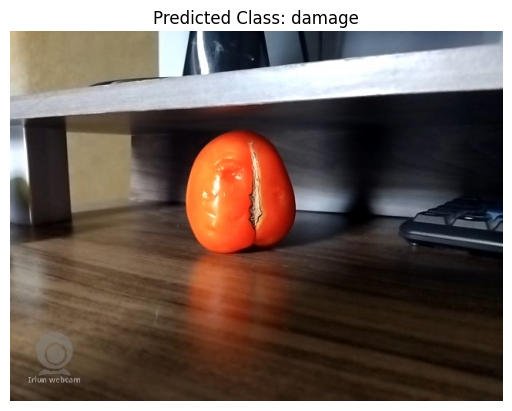

A previsão do modelo é: damage
A previsão está correta? (sim/não): sim


In [39]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

# Função para capturar imagem da webcam
def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = '📷 Capturar Foto';
        div.appendChild(capture);

        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});

        document.body.appendChild(div);
        div.appendChild(video);
        video.srcObject = stream;
        await video.play();

        // Ajustar o tamanho da saída para o tamanho do vídeo
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        // Esperar o botão ser clicado
        await new Promise((resolve) => capture.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getVideoTracks()[0].stop();
        div.remove();

        const dataUrl = canvas.toDataURL('image/jpeg', quality);
        return dataUrl;
    }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    if not data:
        raise Exception("Nenhuma imagem foi capturada")
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

# Função para carregar e processar a imagem
def load_and_preprocess_image(img_path):
    img = image.load_img(img_path, target_size=(150, 150))  # Ajuste o tamanho conforme necessário
    img_array = image.img_to_array(img)  # Converte a imagem em um array
    img_array = np.expand_dims(img_array, axis=0)  # Adiciona uma dimensão para o batch
    img_array /= 255.0  # Normaliza a imagem
    return img_array

# Função para coletar feedback
def get_feedback(predicted_label):
    print(f'A previsão do modelo é: {predicted_label}')
    feedback = input('A previsão está correta? (sim/não): ').strip().lower()
    if feedback == 'não':
        correct_label = input('Qual é a classe correta? (damage, old, ripe, unripe): ').strip().lower()
        return correct_label
    return None

# Função para salvar a imagem corrigida
def save_corrected_image(img_path, correct_label):
    label_dir = os.path.join(train_dir, correct_label)
    os.makedirs(label_dir, exist_ok=True)  # Cria o diretório da classe se não existir
    img_name = os.path.basename(img_path)
    corrected_path = os.path.join(label_dir, img_name)
    # Salva a imagem corrigida na pasta correta
    image.save_img(corrected_path, image.load_img(img_path))

# Capturar a imagem da webcam
try:
    img_filename = take_photo()
    print('Foto capturada e salva como {}'.format(img_filename))
    # Carregar e processar a imagem capturada
    img_array = load_and_preprocess_image(img_filename)

    # Fazer a previsão
    prediction = model.predict(img_array)
    predicted_class = np.argmax(prediction)

    # Obter o nome da classe correspondente
    class_names = ['damage', 'old', 'ripe', 'unripe']
    predicted_label = class_names[predicted_class]

    # Plotar a imagem
    plt.imshow(image.load_img(img_filename))
    plt.title(f'Predicted Class: {predicted_label}')
    plt.axis('off')
    plt.show()

    # Coletar feedback do usuário
    correct_label = get_feedback(predicted_label)

    # Se o feedback foi recebido, salvar a imagem na pasta correta
    if correct_label:
        print(f'O feedback recebido foi: A classe correta é {correct_label}.')
        save_corrected_image(img_filename, correct_label)

except Exception as err:
    print('Erro ao capturar foto: {}'.format(err))
